# Листок №3. Прикладные дифференциальные уравнения

Выполнены все пять задач: аналитический вывод, статический PNG и анимация
на `matplotlib.animation.FuncAnimation` с управлением воспроизведением.
Источник условий: листок П. Е. Рябова «Прикладные дифференциальные уравнения».
Численные начальные условия в PDF не заданы, поэтому выбранные примеры явно указаны.
Единицы измерения - СИ, $g=9.81$ м/с². Для скольжения принята гладкая
двусторонняя направляющая, трение отсутствует.

Код моделей находится в `models.py`, код численных проверок - в `checks.py`.
Для повторного расчёта выберите Python из `.venv` и нажмите **Run All**.
Ниже каждой модели анимация имеет ползунок, кнопки запуска/остановки и выбор скорости.
Отдельные HTML в `animations/` можно открыть в обычном браузере.



In [1]:
from pathlib import Path
import re
import matplotlib.pyplot as plt
from IPython.display import display, HTML
import models
from checks import run_checks
get_ipython().run_line_magic('matplotlib', 'inline')
models.setup()
Path('animations').mkdir(exist_ok=True)

def show_animation(index):
    fig, animation, update = models.ANIMATORS[index]()
    html = animation.to_jshtml(fps=15, default_mode='once')
    # Текстовые значки управления доступны даже без внешнего шрифта.
    icons = {'play': '▶', 'pause': 'Ⅱ', 'step-backward': '◀|',
             'step-forward': '|▶', 'fast-backward': '|◀',
             'fast-forward': '▶|', 'backward': '◀', 'forward': '▶',
             'minus': '−', 'plus': '+'}
    for icon, symbol in icons.items():
        html = html.replace(f'<i class="fa fa-{icon}"></i>', symbol)
    html = html.replace('<i class="fa fa-play fa-flip-horizontal"></i>', '◀')
    html = re.sub(r'<link[^>]*font-awesome[^>]*>', '', html)
    html = chr(10).join(line.rstrip() for line in html.splitlines())
    output = Path('animations')/f'3_{index+1}.html'
    output.write_text('<!doctype html><html lang="ru"><meta charset="utf-8">'
                      + '<title>Листок 3 — анимация</title><body>' + html + '</body></html>',
                      encoding='utf-8')
    # Диагностические кадры для проверки изображения.
    qa = Path('.qa'); qa.mkdir(exist_ok=True)
    for frame in [0, models.FRAMES//2, models.FRAMES-1]:
        update(frame)
        fig.savefig(qa/f'3_{index+1}_{frame}.png', dpi=110, bbox_inches='tight')
    plt.close(fig)
    display(HTML(html))
    print('Сохранено:', output)
print('Модели загружены. Для управления используйте кнопки под анимацией.')

Модели загружены. Для управления используйте кнопки под анимацией.


## 3.1. Кривая равномерного вертикального спуска

**Постановка.** Ось $x$ горизонтальна, $y$ направлена вверх. По уточнению в PDF
постоянна вертикальная скорость: $\dot y=-v$, $v>0$; скорость вдоль кривой
не обязана быть постоянной. Пусть $x(0)=x_0$, $y(0)=y_0$, $\dot x(0)=u_0>0$.
Движение с такими начальными скоростями требует начального толчка: это не пуск из покоя.

**Исключение реакции.** Второй закон Ньютона:
$$m\ddot{\mathbf r}=(0,-mg)+\mathbf N.$$
Реакция гладкой направляющей ортогональна скорости, поэтому
$$m(\ddot x\dot x+\ddot y\dot y)=-mg\dot y.$$
Так как $\ddot y=0$, получаем $\dot x\ddot x=gv$. Интегрируя,
$$\dot x=\sqrt{u_0^2+2gvt},\qquad
x=x_0+\frac{(u_0^2+2gvt)^{3/2}-u_0^3}{3gv},\qquad y=y_0-vt.$$

**Дифференциальное уравнение кривой.** Если $p=y'(x)<0$, то
$\dot x=-v/p$ и $\ddot x=-v^2p'/p^3$. Проекция закона Ньютона
на касательную $(1,p)$ даёт $\ddot x=-gp$, откуда
$$p'=\frac g{v^2}p^4,\qquad
p^{-3}=C-\frac{3g}{v^2}x.$$
С учётом начальных условий $p(x_0)=-v/u_0$:
$$y(x)=y_0+\frac{u_0^2}{2g}
-\frac{[u_0^3+3gv(x-x_0)]^{2/3}}{2g},\qquad x\ge x_0.$$
Обозначив $X=x_0-u_0^3/(3gv)$, $Y=y_0+u_0^2/(2g)$, получаем
$$\boxed{(x-X)^2=\frac{8g}{9v^2}(Y-y)^3},\qquad x>X.$$
Это ветвь полукубической параболы. Реакция равна
$\mathbf N=(mgv/\dot x,mg)$; её скалярное произведение со скоростью равно нулю.
Также $\tfrac12(\dot x^2+v^2)+gy=\mathrm{const}$.

На статическом графике: $(v,u_0)=(0.7,1.5),(1,1),(1.4,0.6)$, $x_0=0$, $y_0=3$.
В анимации $v=u_0=1$, $0\le t\le2$ с. Начало движения отмечено точкой.



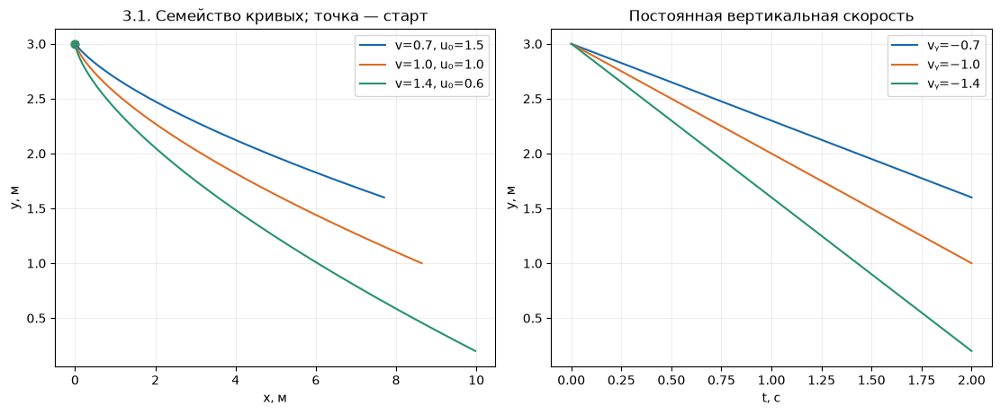

In [2]:
figure = models.PLOTTERS[0]()
plt.show()

In [3]:
show_animation(0)

Сохранено: animations\3_1.html


## 3.2. Бильярд в прямоугольнике

Пусть $0\le x\le a$, $0\le y\le b$, масса $m$. Между ударами
$$\ddot x=\ddot y=0.$$
На вертикальной стенке $v_x\mapsto-v_x$, $v_y$ не меняется;
на горизонтальной - $v_y\mapsto-v_y$, $v_x$ не меняется.
Поэтому $v_x^2+v_y^2$, энергия и модуль скорости сохраняются.
В углу нормаль неоднозначна; траектории с попаданием точно в угол исключаем.

**Метод развёртки.** Вместо отражения шара зеркально отражаем прямоугольник.
В развёрнутой плоскости
$$U(t)=x_0+v_xt,\qquad V(t)=y_0+v_yt.$$
Определим треугольную функцию
$$F_L(q)=L-|\,(q\bmod2L)-L\,|.$$
Тогда точное положение шара
$$x(t)=F_a(U(t)),\qquad y(t)=F_b(V(t)).$$
Склейка противоположных сторон прямоугольника $2a\times2b$ превращает
движение в линейный поток на двумерном торе.

**Периодичность.** При $v_xv_y\ne0$ полный возврат положения и скорости
соответствует
$$v_xT=2am,\qquad v_yT=2bn,\quad m,n\in\mathbb Z.$$
Следовательно, период существует тогда и только тогда, когда
$$\rho=\frac{av_y}{bv_x}\in\mathbb Q.$$
Если $\rho=n/m$ в несократимом виде, $T=2a|m|/|v_x|$.
При осевом движении период равен $2a/|v_x|$ или $2b/|v_y|$.
Для иррационального $\rho$ орбита на торе плотна и равномерно распределена
по площади. Это эргодичность **потока при фиксированном направлении**;
всё фазовое пространство бильярда не эргодично, так как сохраняются
$|p_x|,|p_y|$. Прямоугольный бильярд интегрируем и не является хаотической системой.
Конечный рисунок иллюстрирует, но не доказывает плотность бесконечной орбиты.

**Гамильтонова формулировка.** Внутри области
$$H=\frac{p_x^2+p_y^2}{2m},\quad \dot x=p_x/m,\quad\dot y=p_y/m,
\quad\dot p_x=\dot p_y=0.$$
Жёсткие стенки реализуют закон упругого отражения; на развёрнутом торе
это свободный гамильтонов поток с постоянным импульсом.

Примеры: $a=3$, $b=2$, $(x_0,y_0)=(0.51,0.73)$, $v_x=1$;
для периодического случая $v_y=2/3$, $\rho=1$, $T=6$ с;
для непериодического $v_y=2\sqrt2/3$, $\rho=\sqrt2$.
В анимации одновременно показаны прямоугольник, развёртка и вложенный в 3D тор
для обоих случаев; вложение тора служит визуализацией, а не физической поверхностью движения шара.



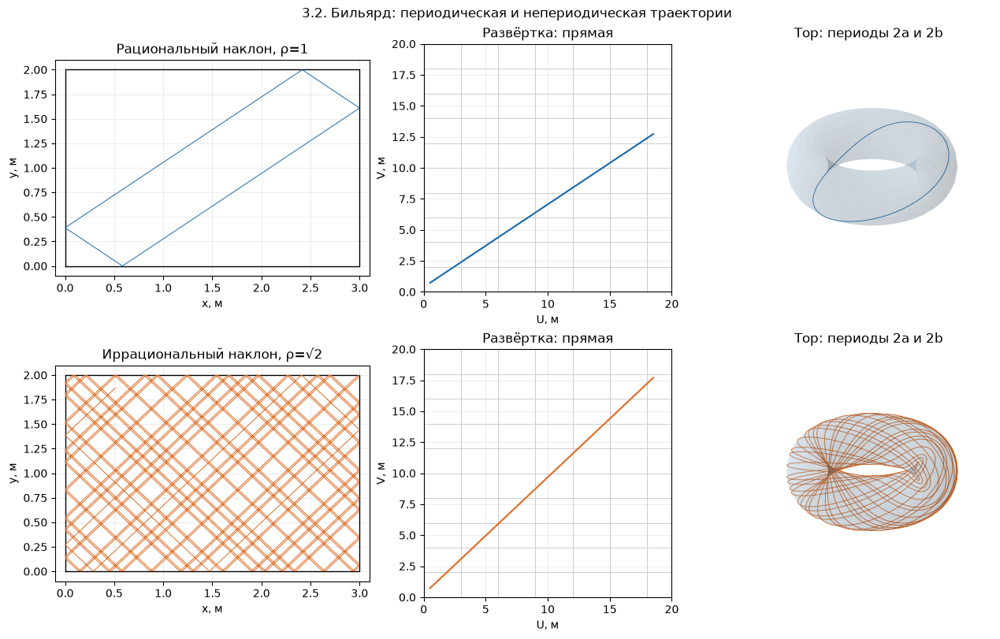

In [4]:
figure = models.PLOTTERS[1]()
plt.show()

In [5]:
show_animation(1)

Сохранено: animations\3_2.html


## 3.3. Цепная линия

Пусть $\mu$ - масса единицы **длины нити**, $T$ - натяжение,
$\alpha$ - угол касательной. Равновесие горизонтальных сил даёт
$$T\cos\alpha=H=\mathrm{const}>0.$$
Так как $\tan\alpha=y'$, вертикальная компонента $T_y=Hy'$.
Вес элемента $ds=\sqrt{1+y'^2}\,dx$ равен $\mu g\,ds$;
из равновесия вертикальных сил
$$H y''\,dx=\mu g\sqrt{1+y'^2}\,dx.$$
Обозначив $a=H/(\mu g)>0$, получаем уравнение
$$y''=\frac1a\sqrt{1+y'^2}.$$
Пусть $p=y'$. Разделяем переменные:
$$\frac{dp}{\sqrt{1+p^2}}=\frac{dx}{a},\qquad
\operatorname{arsinh}p=\frac{x-x_c}{a},\qquad
p=\sinh\frac{x-x_c}{a}.$$
Интегрирование даёт
$$\boxed{y=a\cosh\frac{x-x_c}{a}+C}.$$
Выбором начала координат $x_c=C=0$ получаем требуемое $y=a\operatorname{ch}(x/a)$.
Параметр $a$ имеет размер длины: увеличение горизонтального натяжения
увеличивает $a$, увеличение плотности при фиксированном $H$ уменьшает $a$.

Для симметричных опор $(\pm L/2,0)$ используем
$$y=a[\cosh(x/a)-\cosh(L/(2a))].$$
Провисание $d=a[\cosh(L/(2a))-1]$, длина нити
$\ell=2a\sinh(L/(2a))$, натяжение $T(x)=H\cosh(x/a)$.
Если задано $\ell>L$, параметр $a$ однозначно определяется уравнением длины.

**Смысл анимации.** При фиксированных опорах и длине одной нерастяжимой
нити нельзя произвольно менять $a$. Здесь показано **семейство равновесных
цепей разной длины**, а не динамика растяжения одной цепи. При изменении
$H$ либо $\mu$ длина пересчитывается и выводится на экран. Пролёт $L=3$ м.
Стрелки показывают две силы натяжения и вес выделенного элемента
$x\in[0.35,0.65]$; их векторная сумма равна нулю.



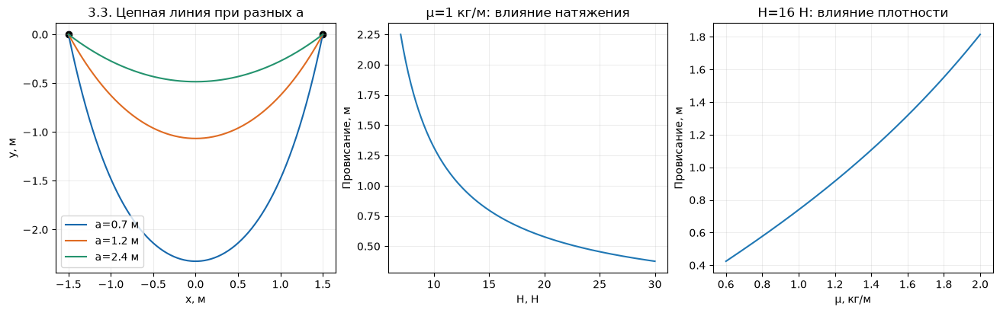

In [6]:
figure = models.PLOTTERS[2]()
plt.show()

In [7]:
show_animation(2)

Сохранено: animations\3_3.html


## 3.4. Таутохрона и уравнение Абеля

Выбираем нижнюю точку $(0,0)$, $y$ вверх. Точка без трения пускается
из покоя с высоты $h>0$. Закон сохранения энергии:
$$\frac{v^2}{2}=g(h-y).$$
Пусть $s(y)$ - длина дуги от нижней точки вверх по одной ветви, $s(0)=0$.
Время спуска
$$T(h)=\frac1{\sqrt{2g}}\int_0^h\frac{s'(y)}{\sqrt{h-y}}\,dy.$$
Требование $T(h)=T_0$ даёт интегральное уравнение Абеля
$$\int_0^h\frac{s'(y)}{\sqrt{h-y}}\,dy=T_0\sqrt{2g}.$$

**Обращение Абеля.** Интегрируем обе части по $h\in[0,Y]$
с весом $(Y-h)^{-1/2}$. После перестановки интегралов внутренний интеграл
$$\int_y^Y\frac{dh}{\sqrt{h-y}\sqrt{Y-h}}=\pi$$
(подстановка $h=y+(Y-y)\sin^2u$). Поэтому
$$\pi\int_0^Y s'(y)\,dy=2T_0\sqrt{2gY},\qquad
s(Y)=\frac{2T_0\sqrt{2g}}\pi\sqrt Y.$$
Вводим $R=gT_0^2/\pi^2$:
$$s^2=8Ry,\qquad y=s^2/(8R).$$
Так как $(dx/ds)^2+(dy/ds)^2=1$, $dy/ds=s/(4R)$,
берём $s=4R\sin(\theta/2)$, $|\theta|<\pi$, и интегрируем:
$$\boxed{x=R(\theta+\sin\theta),\qquad y=R(1-\cos\theta).}$$
Это перевёрнутая циклоида с нижней точкой при $\theta=0$.

**Независимость времени.** Касательное уравнение движения
$$\ddot s=-g\frac{dy}{ds}=-\frac g{4R}s.$$
Если $s(0)=s_0\ne0$, $\dot s(0)=0$, то
$$s(t)=s_0\cos(\omega t),\quad\omega=\sqrt{g/(4R)},\qquad
\boxed{T=\frac\pi{2\omega}=\pi\sqrt{R/g}=T_0}.$$
Время первого достижения низа не зависит от ненулевого $s_0$.
Пуск из самой нижней точки имеет нулевое время; крайние острия исключены.

Визуализация использует $R=1$ м, $\theta_0=0.6,1.4,2.5$ рад.
Образующая окружность радиуса $R$ катится **под** прямой $y=2R$ без скольжения:
для $0\le u\le2\pi$ её центр $(R(u-\pi),R)$, отмеченная точка
$(R(u-\pi-\sin u),R(1+\cos u))$. При $\theta=u-\pi$ это та же циклоида.
Правый кадр анимации показывает построение, его параметр $u$ не является
физическим углом скатывающегося шарика. Левый кадр использует физическое время.



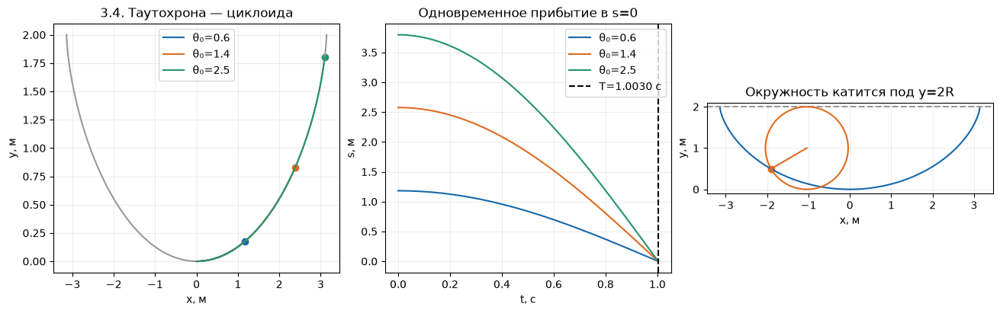

In [8]:
figure = models.PLOTTERS[3]()
plt.show()

In [9]:
show_animation(3)

Сохранено: animations\3_4.html


## 3.5. Математический маятник

Пусть $l$ - длина невесомого стержня, $m$ - масса,
$\theta$ - угол от вертикали вниз. Касательная составляющая силы тяжести
$-mg\sin\theta$ даёт
$$ml\ddot\theta=-mg\sin\theta,\qquad
\boxed{\ddot\theta+\omega_0^2\sin\theta=0},\quad\omega_0=\sqrt{g/l}.$$
Эквивалентная система: $\dot\theta=\Omega$, $\dot\Omega=-\omega_0^2\sin\theta$.

**Малые углы.** При $|\theta|\ll1$ заменяем $\sin\theta\approx\theta$:
$$\theta(t)=\theta_0\cos\omega_0t+\frac{\Omega_0}{\omega_0}\sin\omega_0t,
\qquad T_{\rm lin}=2\pi\sqrt{l/g}.$$

**Энергия и фазовый портрет.** Умножив точное уравнение на $\dot\theta$,
получаем первый интеграл
$$E=\tfrac12ml^2\Omega^2+mgl(1-\cos\theta)=\mathrm{const}.$$
В импульсе $p=ml^2\Omega$ гамильтониан
$H=p^2/(2ml^2)+mgl(1-\cos\theta)$.
Равновесия $(2k\pi,0)$ устойчивы (центры), $((2k+1)\pi,0)$ неустойчивы (сёдла).

- $0<E<2mgl$: колебания, замкнутые фазовые кривые.
- $E=2mgl$: сепаратриса, проход к верхнему положению занимает бесконечное время.
- $E>2mgl$: вращения, угол без свёртки не ограничен.

На $-\pi\le\theta\le\pi$ сепаратриса задаётся
$\Omega=\pm2\omega_0\cos(\theta/2)$. Её ветвь можно записать
$\theta(t)=4\arctan e^{\omega_0(t-t_*)}-\pi$.

**Точное нелинейное решение и период.** Для пуска из покоя
$\theta(0)=A$, $0<A<\pi$, положим $k=\sin(A/2)$.
Из энергии $\dot\theta^2=4\omega_0^2[k^2-\sin^2(\theta/2)]$.
Подстановка $\sin(\theta/2)=k\sin\varphi$ даёт
$$\omega_0t=K(k)-F(\varphi,k),$$
где $F(\varphi,k)=\int_0^\varphi(1-k^2\sin^2u)^{-1/2}du$,
$K(k)=F(\pi/2,k)$. Следовательно,
$$\theta(t)=2\arcsin[k\,\operatorname{sn}(K(k)-\omega_0t,k)],\qquad
\boxed{T(A)=4\sqrt{l/g}\,K(k)}.$$
В SciPy аргумент `ellipk` и `ellipj` - **параметр $m=k^2$**, не модуль $k$.
При $A\to0$ получаем $T_{\rm lin}$, при $A\to\pi$ период стремится к бесконечности.
Для произвольной начальной скорости энергия задаёт квадратуру
$dt=\pm d\theta/\sqrt{2E/(ml^2)-2\omega_0^2(1-\cos\theta)}$;
знак выбирают по направлению движения, при повороте ветвь меняют.

Для $l=1$ м показаны $(\theta_0,\Omega_0)=(0.15,0),(2.6,0),(0,2.4\sqrt g)$.
Численное решение `solve_ivp(DOP853)` проверяется по сохранению энергии
и сравнением с точной эллиптической формулой. Фазовый угол свёрнут в
$[-\pi,\pi)$, а график $\theta(t)$ отображает полный угол вращения.

## Источники и ограничения

Условия предоставлены пользователем: «Практические занятия Листок 3 (2).pdf»,
составитель П. Е. Рябов. Исходный PDF не включается в публичный репозиторий.
Все выводы записаны для идеальных моделей: без трения, сопротивления и деформации стержня.
Анимация цепи показывает семейство статических равновесий с разной длиной.

Дополнительные материалы для сверки математических формул:

- [L. Panizzi: The Cycloid and the Tautochrone Problem](https://appliedmath.brown.edu/sites/default/files/fractional/22%20The%20Cycloid%20and%20the%20Tautochrone%20Problem.pdf).
- [J. P. Juchem Neto: Nonlinear Pendulum: A Simple Generalization](https://arxiv.org/abs/1007.4026).

Код проекта написан для этого листка. Все рисунки и анимации воспроизводятся локально.


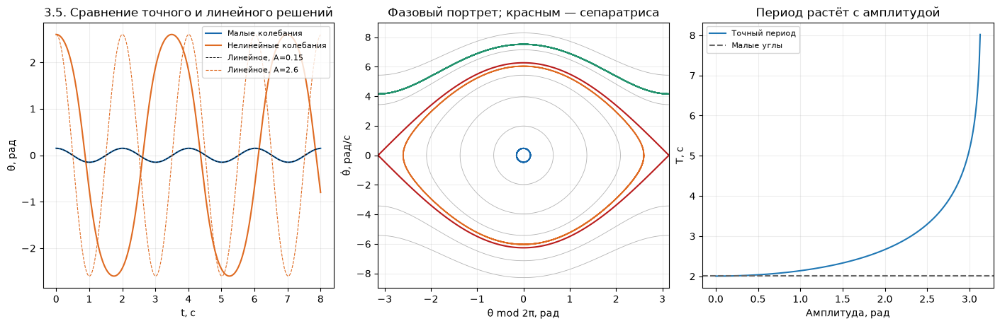

In [10]:
figure = models.PLOTTERS[4]()
plt.show()

In [11]:
show_animation(4)

Сохранено: animations\3_5.html


## Проверка результатов

Проверяем физические инварианты, формулы и независимость времени спуска.

In [12]:
for label, value in run_checks().items():
    print(label, ':', value)

3.1: энергия, явная кривая, постоянство vy : OK
3.2: границы, скорость, период T=6, тор : OK
3.3: ОДУ цепной линии, баланс сил : OK
3.4: интеграл Абеля и времена прибытия : [1.0030333403560756, 1.0030333403560556, 1.0030333403550997]
3.5: ошибка точного решения : 4.732445546551389e-10
3.5: относительный дрейф энергии : 6.808009813389493e-11
